# EDA v2: прокси-датасеты для оценки поисковой выдачи банка

> **Прокси до получения данных банка.** Реальных запросов, выдачи и разметки Альфа-Банка у команды пока нет: первые примеры разметки ожидаются до 13.11.2026, полный набор — к 20.11.2026. Все числа ниже посчитаны на **публичных прокси-датасетах** и на **синтетическом каталоге фич** (помечен как допущение). Выводы о данных банка — гипотезы, которые проверим тем же кодом на реальной выгрузке.

Это вторая версия EDA. После аудита прокси основным датасетом для метрик выдачи стал WANDS (реальная выдача с разметкой пар «запрос–товар»), для судьи — ESCI LLM-judged, а BANKING77 и MASSIVE остались во вспомогательных ролях. Первая версия ([`01_eda_proxy.ipynb`](01_eda_proxy.ipynb)) сохранена как дополнительный анализ свойств текста: опечатки, морфология, согласие разметчиков MASSIVE.

**Что моделирует наш проект и что нужно от прокси.** Агент вводит запрос в поиск приложения, снимает топ-3, LLM-судья ставит каждой позиции оценку 0/1/2 против ручной разметки «запрос → ожидаемая фича», код считает R3 и NDCG@3 и подсвечивает просадки после релиза. Значит, прокси нужны: (1) короткие поисковые запросы, (2) пары «запрос–документ» с градуированной разметкой, (3) реальная выдача, которую можно «сломать», (4) оценки LLM-судьи рядом с человеческими, (5) русский банковский язык.

| Раздел | Датасет | Роль |
| --- | --- | --- |
| 1 | все | Паспорт: что каждый датасет моделирует и что нет |
| 2 | WANDS | Основной: метки 0/1/2, бейзлайн BM25, R3 и NDCG@3, просадки на реальной выдаче |
| 3 | ESCI LLM-judged | Согласие LLM-судьи с людьми, модель шума судьи |
| 4 | BANKING77 + banking77_ru | Банковские интенты: что решается поиском, русские формулировки, объём разметки |
| 5 | Синтетический каталог Альфа-Банка | Формат будущей разметки банка, бейзлайн на русском, шаблон EDA |
| 6 | MASSIVE ru-RU | Контроль вне домена |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

from mlsd_course.eda import drops
from mlsd_course.eda.bank_template import bank_eda
from mlsd_course.eda.banking_groups import intent_group
from mlsd_course.eda.catalog import (
    b77ru_queries,
    build_qrels,
    load_catalog,
    ssq_queries,
    template_queries,
)
from mlsd_course.eda.judge import ESCI, FOLDS, agreement, confusion, row_normalized
from mlsd_course.eda.loaders import (
    BANK_SERP_COLUMNS,
    load_banking77,
    load_banking77_ru,
    load_esci_judge,
    load_massive_ru,
    load_ssq_ru,
    load_wands,
)
from mlsd_course.eda.ranking import bootstrap_ci, evaluate_run, ndcg_at_k
from mlsd_course.eda.retrieval import BM25, CharTfidf, top_k_run
from mlsd_course.eda.text_stats import duplicates_report, normalize, tokens

FIG = Path("../reports/eda")
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
SEED = 42


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()


def n_words(s: pd.Series) -> pd.Series:
    return s.map(lambda t: len(tokens(t)))


def ci_row(name, m):
    r3, r3l, r3h = bootstrap_ci(m["r3"], seed=SEED)
    nd, ndl, ndh = bootstrap_ci(m["ndcg3"], seed=SEED)
    return {
        "выдача": name,
        "запросов": len(m),
        "R3": f"{r3:.3f} [{r3l:.3f}; {r3h:.3f}]",
        "NDCG@3": f"{nd:.3f} [{ndl:.3f}; {ndh:.3f}]",
        "R3 строгий (rel=2)": round(m["r3_exact"].mean(), 3),
    }

## 1. Паспорт прокси-датасетов

Загружаем все датасеты и считаем одни и те же характеристики запросов: длину, долю коротких запросов (до 4 слов — типичная длина поискового запроса), наличие пар «запрос–документ» с разметкой.

In [2]:
w = load_wands()
esci = load_esci_judge()
b77 = load_banking77()
b77ru = load_banking77_ru()
ssq = load_ssq_ru()
ru = load_massive_ru()
cat = load_catalog()

texts = {
    "WANDS": w["query"]["query"],
    "ESCI LLM-judged": esci["queries"]["query"],
    "BANKING77 (en)": b77["text"],
    "banking77_ru": b77ru["text"],
    "synthetic-search-queries-ru (фин.)": ssq["text"],
    "MASSIVE ru-RU": ru["text"],
}
passport = pd.DataFrame(
    {
        name: {
            "строк": len(t),
            "медиана слов": float(n_words(t).median()),
            "доля ≤ 4 слов": round(float((n_words(t) <= 4).mean()), 3),
        }
        for name, t in texts.items()
    }
).T
passport["пары запрос–документ с меткой"] = [
    f"{len(w['label'])} (0/1/2)",
    f"{len(esci['judgments'])} (E/S/C/I)",
    "нет",
    "нет",
    "нет",
    "нет",
]
passport

,строк,медиана слов,доля ≤ 4 слов,пары запрос–документ с меткой
WANDS,480.0,3.0,0.831,233448 (0/1/2)
ESCI LLM-judged,1000.0,4.0,0.708,21292 (E/S/C/I)
BANKING77 (en),13083.0,10.0,0.018,нет
banking77_ru,13083.0,8.0,0.065,нет
synthetic-search-queries-ru (фин.),923.0,8.0,0.063,нет
MASSIVE ru-RU,16521.0,5.0,0.359,нет


**Паспорт: что моделирует и чего не моделирует каждый датасет**

| Датасет | Домен | Язык | Форма запросов | Метки | Пары query–doc | Лицензия | Роль в проекте | Моделирует | Не моделирует |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| [WANDS](https://github.com/wayfair/WANDS) | e-commerce (мебель, дом) | en | короткие поисковые | Exact / Partial / Irrelevant → 2/1/0 | да, 233 448 | MIT | **основной**: метрики выдачи, бейзлайн, просадки | градуированную разметку, реальную выдачу, запросы без точного ответа | банковский домен, русский язык, топ-3 из десятков фич |
| [ESCI LLM-judged top-10](https://huggingface.co/datasets/johannhartmann/esci-llm-judged-top10) | e-commerce (Amazon) | en | короткие поисковые | E/S/C/I, судья и человек | да, 21 292 + 1 500 калибровочных | Apache-2.0 | **судья**: согласие с людьми, модель шума | ошибки LLM-судьи, путаницу соседних классов | банковский домен, наш промпт и модели AlfaGen |
| [BANKING77](https://huggingface.co/datasets/PolyAI/banking77) | банк (необанк) | en | обращения в поддержку | 77 интентов | нет | CC BY 4.0 | словарь банковских интентов | близкие интенты, баланс | выдачу, кредиты/вклады/страхование, короткие запросы |
| [banking77_ru](https://huggingface.co/datasets/DeepPavlov/banking77_ru) | банк | ru (перевод) | обращения в поддержку | 77 интентов | нет | в карточке не указана | русские формулировки интентов, кривая обучения | русскую банковскую лексику | живые запросы (это перевод), выдачу |
| [synthetic-search-queries-ru](https://huggingface.co/datasets/EmbeddingStudio/synthetic-search-queries-ru) | много отраслей, 9 финансовых | ru | поисковые, сгенерированы GPT-4 | категория отрасли | нет | Apache-2.0 | русские финансовые запросы для каталога | лексику продуктов (ипотека, вклад, страховка) | реальное распределение запросов, банковское приложение |
| [MASSIVE 1.1 ru-RU](https://github.com/alexa/massive) | голосовой ассистент | ru | короткие команды | 60 интентов | нет | CC BY 4.0 | **контроль вне домена** | разговорный русский, внедоменный поток | банк (финансов 2,5%) |
| Синтетический каталог (`data/synthetic/`) | банк, **допущение** | ru | короткие | 0/1/2 по правилам | да, плотная | наш | формат разметки банка | структуру «запрос → фича», страты | реальный каталог и запросы банка |

## 2. WANDS: разметка пар и реальная выдача

### 2.1. Метки, пары на запрос, запросы без точного ответа

запросов: 480 | товаров: 42994 | размеченных пар: 233448
метки: {'Partial': 0.628, 'Irrelevant': 0.262, 'Exact': 0.11}
пар на запрос: {'min': 1.0, '25%': 122.75, '50%': 216.5, '75%': 523.75, 'max': 4329.0}
запросов без Exact: 101 (21.0%)
запросов без Exact и Partial: 1
слов в запросе: {'min': 1.0, '50%': 3.0, 'mean': 3.4, 'max': 11.0}
классов запросов: 188


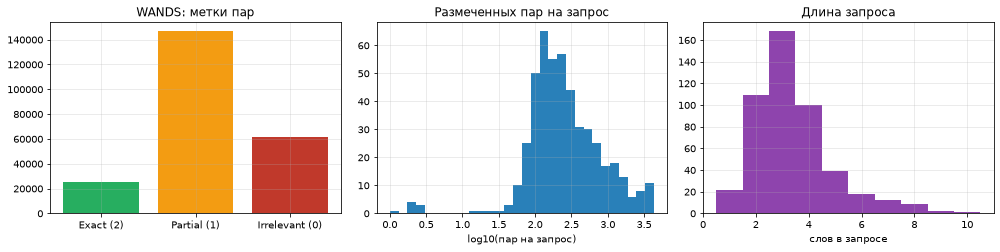

In [3]:
lab, wq, wp = w["label"], w["query"], w["product"]
print("запросов:", len(wq), "| товаров:", len(wp), "| размеченных пар:", len(lab))
print("метки:", lab["label"].value_counts(normalize=True).round(3).to_dict())
per_q = lab.groupby("query_id").agg(
    pairs=("rel", "size"),
    exact=("rel", lambda s: (s == 2).sum()),
    partial=("rel", lambda s: (s == 1).sum()),
)
print("пар на запрос:", per_q["pairs"].describe()[["min", "25%", "50%", "75%", "max"]].to_dict())
print(
    "запросов без Exact:", int((per_q["exact"] == 0).sum()), f"({(per_q['exact'] == 0).mean():.1%})"
)
print("запросов без Exact и Partial:", int(((per_q["exact"] + per_q["partial"]) == 0).sum()))
wq["n_words"] = n_words(wq["query"])
print("слов в запросе:", wq["n_words"].describe()[["min", "50%", "mean", "max"]].round(2).to_dict())
print("классов запросов:", wq["query_class"].nunique())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
vc = lab["label"].value_counts().reindex(["Exact", "Partial", "Irrelevant"])
ax[0].bar(
    ["Exact (2)", "Partial (1)", "Irrelevant (0)"],
    vc.values,
    color=["#27ae60", "#f39c12", "#c0392b"],
)
ax[0].set_title("WANDS: метки пар")
ax[1].hist(np.log10(per_q["pairs"]), bins=30, color="#2980b9")
ax[1].set_xlabel("log10(пар на запрос)")
ax[1].set_title("Размеченных пар на запрос")
ax[2].hist(wq["n_words"], bins=range(1, 12), color="#8e44ad", align="left")
ax[2].set_xlabel("слов в запросе")
ax[2].set_title("Длина запроса")
save(fig, "09_wands_labels.png")

**Выводы.**

- 480 запросов, 42 994 товара, 233 448 размеченных пар. Метки: Partial 62,8%, Irrelevant 26,2%, Exact 11,0%. Разметка градуированная, как наша шкала 0/1/2.
- Пар на запрос — от 1 до 4 329, медиана 216,5: глубина разметки сильно неравномерна.
- У 101 запроса (21,0%) нет ни одного точного ответа (Exact), только частичные. В банке это аналог запроса, на который в каталоге нет целевой фичи: разметка должна это допускать, а метрика — не штрафовать поиск за невозможное.
- Медиана длины запроса — 3 слова, 83,1% запросов не длиннее 4 слов. По форме это ближе всего к поиску в приложении.

### 2.2. Бейзлайн BM25 и метрики R3, NDCG@3

Бейзлайн — BM25 по названию товара, классу и категории (вариант А) и по ним же плюс описанию (вариант Б). Метрики как в `ranking.py` и дизайн-доке:

- **R3** — доля релевантных (rel ≥ 1) позиций в топ-3: `R3 = |{i ≤ 3 : rel_i ≥ 1}| / 3`. Отдельно показываем строгий R3 только по rel = 2.
- **NDCG@3** — DCG@3 с усилением `2^rel − 1`, нормированный на идеальную выдачу из всех размеченных пар запроса.
- Неразмеченная позиция выдачи считается нерелевантной, долю размеченных позиций топ-3 выводим отдельно. Интервалы — перцентильный бутстрап по запросам (2 000 повторов).

In [4]:
qrels_w = lab.rename(columns={"product_id": "doc_id"})[["query_id", "doc_id", "rel"]]
fields_a = (
    wp["product_name"].fillna("")
    + " "
    + wp["product_class"].fillna("")
    + " "
    + wp["category hierarchy"].fillna("")
)
fields_b = fields_a + " " + wp["product_description"].fillna("")
runs_w, metrics_w, rows = {}, {}, []
for name, docs in [
    ("BM25 А: название+класс+категория", fields_a),
    ("BM25 Б: + описание", fields_b),
]:
    bm = BM25(docs.tolist())
    run = top_k_run(
        bm.scores(wq["query"].tolist()), wq["query_id"].tolist(), wp["product_id"].tolist(), k=10
    )
    m = evaluate_run(run, qrels_w)
    top3 = run[run["position"] <= 3].merge(qrels_w, on=["query_id", "doc_id"], how="left")
    strict = top3.groupby("query_id")["rel"].apply(lambda s: (s == 2).sum() / 3).rename("r3_exact")
    m = m.merge(strict, on="query_id")
    runs_w[name], metrics_w[name] = run, m
    rows.append({**ci_row(name, m), "размечено позиций топ-3": round(m["labeled"].mean(), 3)})
pd.DataFrame(rows)

,выдача,запросов,R3,NDCG@3,R3 строгий (rel=2),размечено позиций топ-3
0,BM25 А: название+класс+категория,480,0.769 [0.737; 0.800],0.647 [0.613; 0.681],0.392,0.869
1,BM25 Б: + описание,480,0.794 [0.765; 0.823],0.662 [0.629; 0.692],0.406,0.845


NDCG@3 = 0: 55 запросов; NDCG@3 = 1: 202
NDCG@3 у запросов с Exact / без Exact: 0.651 / 0.632
         size   mean
n_words             
1          22  0.876
2         109  0.666
3         168  0.626
4+        181  0.627

Худшие запросы:
                   query  pairs  exact  ndcg3  labeled
           drudge report      1      0    0.0      0.0
promo codes or discounts      2      0    0.0      0.0
           one alium way      2      0    0.0      0.0
             large bases      2      0    0.0      0.0
          white abstract      2      1    0.0      0.0
       rug for teen room      3      1    0.0      0.0
            minnestrista      3      0    0.0      0.0
       living room ideas     21     16    0.0      0.0


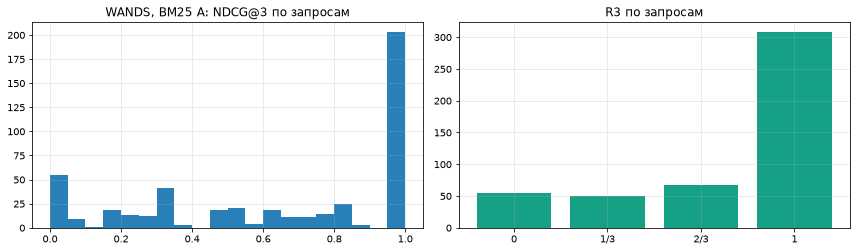

In [5]:
m_a = metrics_w["BM25 А: название+класс+категория"].merge(per_q, on="query_id")
print(
    "NDCG@3 = 0:",
    int((m_a["ndcg3"] == 0).sum()),
    "запросов; NDCG@3 = 1:",
    int((m_a["ndcg3"] == 1).sum()),
)
print(
    "NDCG@3 у запросов с Exact / без Exact:",
    round(m_a.loc[m_a["exact"] > 0, "ndcg3"].mean(), 3),
    "/",
    round(m_a.loc[m_a["exact"] == 0, "ndcg3"].mean(), 3),
)
m_a = m_a.merge(wq[["query_id", "query", "n_words"]], on="query_id")
print(
    m_a.groupby(m_a["n_words"].clip(upper=4))["ndcg3"]
    .agg(["size", "mean"])
    .round(3)
    .rename(index={4: "4+"})
)
print("\nХудшие запросы:")
print(
    m_a.sort_values(["ndcg3", "pairs"])
    .head(8)[["query", "pairs", "exact", "ndcg3", "labeled"]]
    .to_string(index=False)
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(m_a["ndcg3"], bins=20, color="#2980b9")
ax[0].set_title("WANDS, BM25 А: NDCG@3 по запросам")
ax[1].hist(m_a["r3"], bins=[-1 / 6, 1 / 6, 1 / 2, 5 / 6, 7 / 6], color="#16a085", rwidth=0.8)
ax[1].set_xticks([0, 1 / 3, 2 / 3, 1], ["0", "1/3", "2/3", "1"])
ax[1].set_title("R3 по запросам")
save(fig, "10_wands_bm25_metrics.png")

**Выводы.**

- BM25 А: R3 = 0,769 [0,737; 0,800], NDCG@3 = 0,647 [0,613; 0,681]. С описанием (Б): 0,794 и 0,662 — интервалы пересекаются, на 480 запросах разница не значима. **Для проекта:** 480 запросов дают интервал NDCG@3 шириной около ±0,03; сравнивать версии поиска по меньшей выборке рискованно.
- R3 в определении «rel ≥ 1» мягкий: при 63% Partial он 0,769, а строгий R3 по rel = 2 — только 0,392. **Для проекта:** в разметке банка нужно явно договориться, что считается релевантным для R3 (только целевая фича или и смежные), иначе R3 будет завышен.
- 13,1% позиций топ-3 не размечены и засчитаны как нерелевантные — метрика занижена. **Для проекта:** каждый новый документ, появившийся в выдаче после релиза, должен получать оценку (судьи или человека), иначе метрика смешивает «плохо» и «неизвестно».
- 55 запросов с NDCG@3 = 0 и 202 с NDCG@3 = 1: распределение по запросам бимодальное. Однословные запросы проще (NDCG@3 0,876 на 22 запросах), начиная с 2 слов — 0,63–0,67.

### 2.3. Синтетические просадки на реальной выдаче WANDS и детектор с шумным судьёй

> **Синтетика поверх реальных данных.** Базовая выдача — реальный топ-10 BM25 А с человеческой разметкой. «Релиз» портит выдачу 10% запросов одним из четырёх способов (таблица ниже), а ещё у 30% запросов меняет её нейтрально: товар топ-3 меняется на товар из хвоста с той же меткой, метрики по разметке не меняются. Это имитирует обычный релиз, где выдача «дышит» без деградации.

Детектор: запрос подсвечивается, если NDCG@3 по оценкам судьи упал на τ и больше. Судья ошибается по одной из моделей шума: равномерно 5% и 10% (ошибка — любая из двух других меток) или **как LLM-судья в ESCI** (матрица P(судья | человек) из раздела 3, свёрнутая в 2/1/0). Два режима: судья заново оценивает обе выдачи (**без кэша**) или вердикт пары «запрос–товар» **кэшируется** между прогонами, и судья оценивает только новые пары. Точность и полнота — суммарно по 10 случайным релизам.

In [6]:
pd.Series(drops.DROP_KINDS, name="тип деградации")

swap_1_3                                           позиции 1 и 3 меняются местами
shift_best_4                лучшая по разметке позиция топ-3 уезжает на 4-е место
evict_1          одна релевантная позиция топ-3 вытесняется нерелевантным товаром
evict_all       все релевантные позиции топ-3 вытесняются нерелевантными товарами
Name: тип деградации, dtype: str

In [7]:
r = runs_w["BM25 А: название+класс+категория"].merge(qrels_w, on=["query_id", "doc_id"], how="left")
r = r.fillna({"rel": 0}).sort_values(["query_id", "position"])
serps = {
    q: list(zip(g["doc_id"], g["rel"].astype(int), strict=True)) for q, g in r.groupby("query_id")
}
ideal = qrels_w.groupby("query_id")["rel"].apply(list).to_dict()
in_top = set(zip(r["query_id"], r["doc_id"], strict=True))
pools = {
    q: [d for d in g["doc_id"] if (q, d) not in in_top]
    for q, g in qrels_w[qrels_w["rel"] == 0].groupby("query_id")
}
fold3 = FOLDS["наша шкала 2/1/0 (E→2, S→1, C+I→0)"]
cal = esci["calibration"]
esci_conf = row_normalized(cal["human_label"].map(fold3), cal["judge_label"].map(fold3), [0, 1, 2])
noise_models = {
    "без ошибок": drops.uniform_confusion(0.0),
    "5%": drops.uniform_confusion(0.05),
    "10%": drops.uniform_confusion(0.10),
    "как ESCI-судья": esci_conf,
}
print(
    "Модель шума «как ESCI-судья», P(судья | человек), строки — человек 0/1/2:\n",
    esci_conf.round(3),
)


def ndcg_of(serp, q):
    return ndcg_at_k([x for _, x in serp], 3, ideal[q])


rows, real_rows = [], []
for kind in drops.DROP_KINDS:
    for seed in range(10):
        cur, real = drops.simulate_release(
            serps, ideal, pools, kind, share=0.1, benign_share=0.3, seed=seed
        )
        real_rows += [{"тип": kind, "Δ": ndcg_of(cur[q], q) - ndcg_of(serps[q], q)} for q in real]
        for noise, conf in noise_models.items():
            for cache in [False, True]:
                for tau in [0.1, 0.2, 0.3]:
                    f = drops.detect(
                        serps, cur, ideal, conf, tau, cache=cache, require_change=False, seed=seed
                    )
                    rows.append(
                        {
                            "тип": kind,
                            "шум": noise,
                            "кэш": cache,
                            "τ": tau,
                            "реальных": len(real),
                            "flagged": len(f),
                            "tp": len(f & real),
                        }
                    )
sim = pd.DataFrame(rows)
real_df = pd.DataFrame(real_rows)
print("\nРеальные просадки за 10 релизов (по человеческой разметке):")
print(real_df.groupby("тип")["Δ"].agg(просадок="size", средний_ΔNDCG3="mean").round(3))
tab = sim.groupby(["тип", "шум", "кэш", "τ"], as_index=False)[["flagged", "tp", "реальных"]].sum()
tab["precision"] = (tab["tp"] / tab["flagged"]).round(3)
tab["recall"] = (tab["tp"] / tab["реальных"]).round(3)
tab[tab["τ"] == 0.2].pivot_table(
    index=["тип", "шум"], columns="кэш", values=["precision", "recall"]
).round(3)

Модель шума «как ESCI-судья», P(судья | человек), строки — человек 0/1/2:
 [[0.587 0.204 0.209]
 [0.179 0.557 0.264]
 [0.105 0.216 0.679]]



Реальные просадки за 10 релизов (по человеческой разметке):
              просадок  средний_ΔNDCG3
тип                                   
evict_1            414          -0.389
evict_all          414          -0.687
shift_best_4       225          -0.258
swap_1_3           139          -0.191


precision        recall       
кэш                             False  True   False  True 
тип          шум                                          
evict_1      10%                0.276  0.800  0.650  0.618
             5%                 0.424  0.894  0.691  0.652
             без ошибок         1.000  1.000  0.715  0.715
             как ESCI-судья     0.118  0.489  0.459  0.464
evict_all    10%                0.335  0.845  0.857  0.841
             5%                 0.486  0.919  0.889  0.879
             без ошибок         1.000  1.000  0.908  0.908
             как ESCI-судья     0.154  0.556  0.621  0.609
shift_best_4 10%                0.124  0.587  0.462  0.524
             5%                 0.217  0.739  0.502  0.529
             без ошибок         1.000  1.000  0.547  0.547
             как ESCI-судья     0.054  0.249  0.378  0.373
swap_1_3     10%                0.073  0.441  0.424  0.482
             5%                 0.126  0.600  0.424  0.475
             без ошибок         1.000  1.000  0.496  0.496
             как ESCI-судья     0.036  0.161  0.396  0.345

Влияние порога τ (среднее по типам деградации):
                     precision               recall              
τ                          0.1    0.2    0.3    0.1    0.2    0.3
шум            кэш                                               
10%            False     0.190  0.202  0.230  0.769  0.598  0.450
               True      0.652  0.668  0.629  0.794  0.616  0.415
5%             False     0.296  0.313  0.333  0.823  0.626  0.459
               True      0.786  0.788  0.725  0.840  0.634  0.434
без ошибок     False     1.000  1.000  1.000  0.897  0.666  0.471
               True      1.000  1.000  1.000  0.897  0.666  0.471
как ESCI-судья False     0.086  0.090  0.097  0.563  0.464  0.384
               True      0.332  0.364  0.362  0.576  0.448  0.298


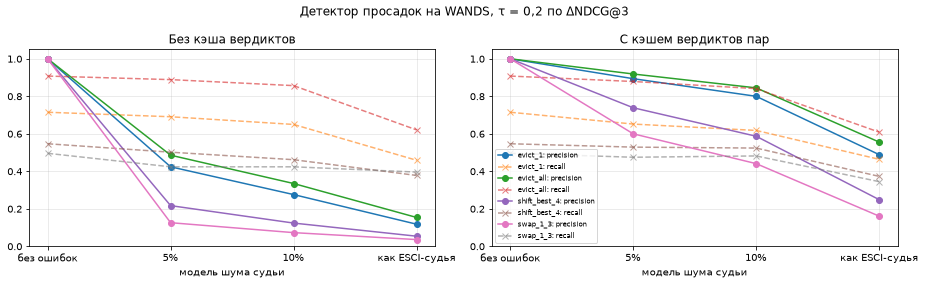

In [8]:
print("Влияние порога τ (среднее по типам деградации):")
print(tab.groupby(["шум", "кэш", "τ"])[["precision", "recall"]].mean().round(3).unstack("τ"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t2 = tab[tab["τ"] == 0.2]
for ax, cache in zip(axes, [False, True], strict=True):
    sub = t2[t2["кэш"] == cache]
    for kind, g in sub.groupby("тип"):
        g = g.set_index("шум").reindex(list(noise_models))
        ax.plot(list(noise_models), g["precision"], marker="o", label=f"{kind}: precision")
        ax.plot(
            list(noise_models), g["recall"], marker="x", ls="--", alpha=0.6, label=f"{kind}: recall"
        )
    ax.set_title("Без кэша вердиктов" if not cache else "С кэшем вердиктов пар")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("модель шума судьи")
axes[1].legend(fontsize=7, loc="lower left")
fig.suptitle("Детектор просадок на WANDS, τ = 0,2 по ΔNDCG@3")
save(fig, "11_wands_drop_detection.png")

**Выводы.**

- Сила деградаций по человеческой разметке: вытеснение всех релевантных из топ-3 — ΔNDCG@3 = −0,687 в среднем, одной — −0,389, сдвиг лучшей позиции на 4-е место — −0,258, перестановка 1 и 3 — −0,191. Перестановку внутри топ-3 R3 не видит вовсе.
- Без шума детектор с τ = 0,2 точен (precision 1,0), но ловит 50–91% просадок: слабые перестановки ниже порога.
- **Шум судьи убивает точность без кэша.** При 5% ошибок на позицию precision падает до 0,31 (среднее по типам), при 10% — до 0,20, при шуме «как ESCI-судья» — до 0,09: почти все тревоги ложные, потому что 30% выдач изменились нейтрально, и судья их переоценил.
- **Кэш вердиктов пар возвращает точность:** 0,79 при 5%, 0,67 при 10% и 0,36 при шуме ESCI-судьи, полнота почти не меняется. Повышение τ с 0,1 до 0,3 почти не поднимает precision (0,79 → 0,73 при 5% и кэше), но вдвое режет полноту (0,84 → 0,43).
- **Для проекта:** (1) кэшировать вердикты пар «запрос–фича» и оценивать только новые пары; (2) просадку подтверждать фактом изменения снятой выдачи; (3) при шуме уровня ESCI-судьи одиночный вердикт недостаточен — нужна калибровка судьи, голосование нескольких прогонов или эскалация человеку для подсвеченных запросов.

## 3. ESCI LLM-judged: согласие LLM-судьи с людьми

1 500 калибровочных пар Amazon ESCI размечены людьми и вслепую оценены LLM-судьёй по той же шкале E/S/C/I (Exact, Substitute, Complement, Irrelevant). Это прямой прокси нашего этапа калибровки: судья против ручной разметки команды поиска. Всё пересчитано по данным, а не взято из карточки датасета.

In [9]:
print(
    "судья:",
    cal["judge_model"].unique().tolist(),
    "| страты:",
    cal["stratum"].value_counts().to_dict(),
)
print("метки людей:", cal["human_label"].value_counts().reindex(ESCI).to_dict())
rows = []
for sub_name, sub in [("все", cal), *list(cal.groupby("stratum"))]:
    for fold_name, fold in FOLDS.items():
        rows.append(
            {
                "пары": sub_name,
                "шкала": fold_name,
                **agreement(sub["human_label"], sub["judge_label"], fold),
            }
        )
pd.DataFrame(rows).round(3)

судья: ['claude-haiku-4-5-20251001'] | страты: {'pooled': 1000, 'not_pooled': 500}
метки людей: {'E': 773, 'S': 497, 'C': 63, 'I': 167}


,пары,шкала,n,accuracy,kappa,kappa_quadratic
0,все,E/S/C/I (4 класса),1500,0.609,0.380,NaN
1,все,"наша шкала 2/1/0 (E→2, S→1, C+I→0)",1500,0.625,0.393,0.449
2,все,E против остальных,1500,0.715,0.432,NaN
3,все,E+S против C+I,1500,0.823,0.400,NaN
4,not_pooled,E/S/C/I (4 класса),500,0.526,0.311,NaN
5,not_pooled,"наша шкала 2/1/0 (E→2, S→1, C+I→0)",500,0.544,0.317,0.410
6,not_pooled,E против остальных,500,0.712,0.330,NaN
7,not_pooled,E+S против C+I,500,0.744,0.393,NaN
8,pooled,E/S/C/I (4 класса),1000,0.651,0.381,NaN
9,pooled,"наша шкала 2/1/0 (E→2, S→1, C+I→0)",1000,0.665,0.398,0.405


           судья E  судья S  судья C  судья I
человек E      525      167       23       58
человек S      131      277       11       78
человек C       17       10       26       10
человек I       31       37       13       86
precision судьи по классам: {'E': np.float64(0.746), 'S': np.float64(0.564), 'C': np.float64(0.356), 'I': np.float64(0.371)}
recall судьи по классам: {'E': np.float64(0.679), 'S': np.float64(0.557), 'C': np.float64(0.413), 'I': np.float64(0.515)}

Самые частые расхождения (человек→судья): {'E→S': 167, 'S→E': 131, 'S→I': 78, 'E→I': 58, 'I→S': 37, 'I→E': 31}
доля E↔S среди всех расхождений: 0.509


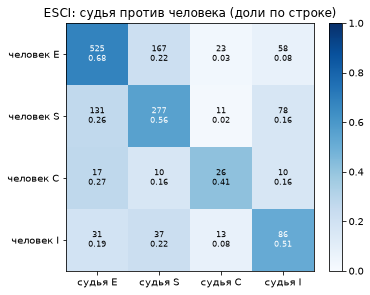

In [10]:
cm = confusion(cal["human_label"], cal["judge_label"], ESCI)
print(cm)
both = {c: ((cal["judge_label"] == c) & (cal["human_label"] == c)).sum() for c in ESCI}
print(
    "precision судьи по классам:",
    {c: round(both[c] / (cal["judge_label"] == c).sum(), 3) for c in ESCI},
)
print(
    "recall судьи по классам:",
    {c: round(both[c] / (cal["human_label"] == c).sum(), 3) for c in ESCI},
)
off = cal[cal["human_label"] != cal["judge_label"]]
pairs_err = (off["human_label"] + "→" + off["judge_label"]).value_counts()
print("\nСамые частые расхождения (человек→судья):", pairs_err.head(6).to_dict())
print(
    "доля E↔S среди всех расхождений:", round(pairs_err.reindex(["E→S", "S→E"]).sum() / len(off), 3)
)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
norm = cm.to_numpy() / cm.to_numpy().sum(axis=1, keepdims=True)
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(
            j,
            i,
            f"{cm.iat[i, j]}\n{norm[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if norm[i, j] > 0.5 else "black",
        )
ax.set_xticks(range(4), [f"судья {c}" for c in ESCI])
ax.set_yticks(range(4), [f"человек {c}" for c in ESCI])
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("ESCI: судья против человека (доли по строке)")
save(fig, "12_esci_judge_confusion.png")

In [11]:
# Примеры расхождений с объяснением судьи.
for kind in ["E→S", "E→I", "S→E", "I→E"]:
    h, j = kind.split("→")
    ex = cal[(cal["human_label"] == h) & (cal["judge_label"] == j)].sample(2, random_state=SEED)
    for _, x in ex.iterrows():
        print(
            f"[{kind}] «{x['query']}» → {x['product_title'][:80]}\n    судья: {x['judge_reason']}"
        )

[E→S] «cream leather sofa» → SETORE 58" Modern Cream Love Seats Furniture, Mid Century Sofa Couch for Living 
    судья: Velvet sofa, not leather; color is beige, not cream.
[E→S] «deck bench brackets» → YUMORE Shelf Bracket 14", Max Load: 440lb Heavy Duty Stainless Steel Solid Shelf
    судья: Shelf bracket, not specifically for deck benches; general-purpose L-bracket.
[E→I] «jvc lt-22mar400» → JVC Stereo Car Single DIN In-Dash CD MP3 Car Stereo Receiver Front USB AUX Input
    судья: JVC car stereo receiver, not a TV model LT-22MAR400.
[E→I] «kms molding paste» → 8 Oz Molding Paste
    судья: Molding paste but Golden Artist Colors brand, not KMS; art supply not hair product.
[S→E] «lg stereo system for home» → PHILIPS Bluetooth Stereo System for Home with CD Player, Wireless Streaming, MP3
    судья: Philips Bluetooth stereo system with CD, MP3, USB, FM radio for home.
[S→E] «tile gap filler» → Pre-Mixed Tile Grout Repair Pen&Tube Grout Pen, Ideal Waterproof to Restore The 
    судья

In [12]:
# Как шум судьи переходит в ошибку метрик запроса. Полной выдачи с оценками и людей, и судьи
# вслепую в датасете нет (у пар с judge_label_blind обычно одна позиция на запрос), поэтому берём
# запросы, где все 3 позиции BM25 размечены людьми, и 20 раз «оцениваем» их судьёй, выбирая
# метку по эмпирической матрице P(судья | человек) из калибровки (шкала 2/1/0).
jd = esci["judgments"]
hb = jd[(jd["label_source"] == "human") & (jd["rank_bm25"] <= 3)]
full = hb.groupby("query_id").filter(lambda g: len(g) == 3).sort_values(["query_id", "rank_bm25"])
idl = (
    jd[jd["label_source"] == "human"]
    .groupby("query_id")["label"]
    .apply(lambda s: s.map(fold3).tolist())
    .to_dict()
)
rng = np.random.default_rng(SEED)
rows = []
for qid, g in full.groupby("query_id"):
    h = g["label"].map(fold3).to_numpy()
    nh = ndcg_at_k(list(h), 3, idl[qid])
    for _ in range(20):
        j = [int(rng.choice(3, p=esci_conf[x])) for x in h]
        rows.append(
            {
                "query_id": qid,
                "ndcg_h": nh,
                "ndcg_j": ndcg_at_k(j, 3, idl[qid]),
                "r3_h": (h > 0).mean(),
                "r3_j": np.mean([x > 0 for x in j]),
            }
        )
nj = pd.DataFrame(rows)
print("запросов ESCI с полным топ-3 BM25, размеченным людьми:", full["query_id"].nunique())
print(
    "MAE NDCG@3 (судья по эмпирическому шуму vs люди):",
    round((nj["ndcg_h"] - nj["ndcg_j"]).abs().mean(), 3),
)
print(
    "средний NDCG@3: люди", round(nj["ndcg_h"].mean(), 3), "/ судья", round(nj["ndcg_j"].mean(), 3)
)
print("R3 запроса совпал:", round((nj["r3_h"] == nj["r3_j"]).mean(), 3))
per_q_mae = nj.assign(e=(nj["ndcg_h"] - nj["ndcg_j"]).abs()).groupby("query_id")["e"].mean()
print("доля запросов, где средняя |ΔNDCG@3| от шума ≥ 0,2:", round((per_q_mae >= 0.2).mean(), 3))

запросов ESCI с полным топ-3 BM25, размеченным людьми: 252
MAE NDCG@3 (судья по эмпирическому шуму vs люди): 0.233
средний NDCG@3: люди 0.78 / судья 0.668
R3 запроса совпал: 0.626
доля запросов, где средняя |ΔNDCG@3| от шума ≥ 0,2: 0.631


**Выводы.**

- По данным пересчитано: 4 класса — accuracy 0,609, κ 0,380; наша шкала 2/1/0 — accuracy 0,625, κ 0,393, квадратичная κ 0,449; «E против остальных» — 0,715 и 0,432; «E+S против C+I» — 0,823 и 0,400. Числа совпадают с карточкой датасета.
- Половина расхождений (50,9%) — путаница соседних классов E и S: судья строже людей к атрибутам («не та кожа», «не тот цвет»). C и I судья определяет плохо: precision 0,356 и 0,371.
- На парах из реальной выдачи (pooled) судья точнее, чем на остальных: 0,651 против 0,526 по 4 классам. **Для проекта:** калибровку проводим на парах из реальной выдачи нашего поиска, а не на случайных парах.
- Перенос шума в метрики (симуляция на 252 запросах с полным топ-3, размеченным людьми): MAE NDCG@3 = 0,233, судья систематически занижает NDCG@3 (0,668 против 0,780), R3 запроса совпадает в 62,6% случаев.
- **Для проекта:** судью нельзя ставить «из коробки». Калибруем его на разметке Полины (первые примеры — в промпт, остальное — отложенная проверка), отдельно меряем согласие по бинарной свёртке «целевая фича / нет», а порог детектора просадок выбираем с учётом измеренной матрицы ошибок судьи.

## 4. BANKING77 и banking77_ru: что из банковских интентов решается поиском

Группировка 77 интентов на «поиск» (фича приложения), «справка» (FAQ, тарифы) и «тикет» (инцидент по операции) сделана **вручную** и зафиксирована в [`banking_groups.py`](../src/mlsd_course/eda/banking_groups.py) — это допущение.

        интентов  строк  доля строк
group                              
search        24   3765       0.288
faq           15   2300       0.176
ticket        38   7018       0.536

RU и EN совпадают по размеру: True | интенты совпадают: True
                   EN     RU
медиана слов   10.000  8.000
доля ≤ 4 слов   0.018  0.065
доля ≤ 6 слов   0.146  0.276

RU по группам, медиана слов: {'faq': 8.0, 'search': 8.0, 'ticket': 9.0}
RU-строк без кириллицы (остались непереведёнными): 2 | пример: ['Google play top up help?', 'Apple watch top up help, please?']


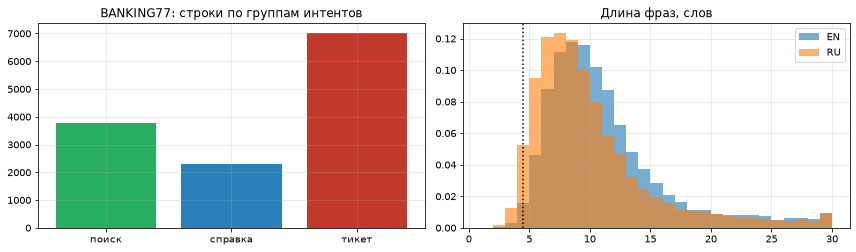

In [13]:
b77["group"] = b77["intent"].map(intent_group)
b77ru["group"] = b77ru["intent"].map(intent_group)
grp = pd.DataFrame(
    {"интентов": b77.groupby("group")["intent"].nunique(), "строк": b77["group"].value_counts()}
)
grp["доля строк"] = (grp["строк"] / grp["строк"].sum()).round(3)
print(grp.reindex(["search", "faq", "ticket"]))
print(
    "\nRU и EN совпадают по размеру:",
    len(b77ru) == len(b77),
    "| интенты совпадают:",
    set(b77ru["intent"]) == set(b77["intent"]),
)
b77["n_words"], b77ru["n_words"] = n_words(b77["text"]), n_words(b77ru["text"])
lens = pd.DataFrame(
    {
        "EN": [b77["n_words"].median(), (b77["n_words"] <= 4).mean(), (b77["n_words"] <= 6).mean()],
        "RU": [
            b77ru["n_words"].median(),
            (b77ru["n_words"] <= 4).mean(),
            (b77ru["n_words"] <= 6).mean(),
        ],
    },
    index=["медиана слов", "доля ≤ 4 слов", "доля ≤ 6 слов"],
).round(3)
print(lens)
print("\nRU по группам, медиана слов:", b77ru.groupby("group")["n_words"].median().to_dict())
no_cyr = ~b77ru["text"].str.contains(r"[А-Яа-яЁё]")
print(
    "RU-строк без кириллицы (остались непереведёнными):",
    int(no_cyr.sum()),
    "| пример:",
    b77ru.loc[no_cyr, "text"].head(3).tolist(),
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(
    ["поиск", "справка", "тикет"],
    grp.reindex(["search", "faq", "ticket"])["строк"],
    color=["#27ae60", "#2980b9", "#c0392b"],
)
ax[0].set_title("BANKING77: строки по группам интентов")
bins = range(1, 31)
ax[1].hist(b77["n_words"], bins=bins, alpha=0.6, label="EN", density=True)
ax[1].hist(b77ru["n_words"], bins=bins, alpha=0.6, label="RU", density=True)
ax[1].axvline(4.5, color="k", ls=":")
ax[1].legend()
ax[1].set_title("Длина фраз, слов")
save(fig, "13_banking77_groups_lengths.png")

In [14]:
rep = duplicates_report(b77ru)
print({k: v for k, v in rep.items() if k != "conflict_examples"})
print("примеры конфликтов:", rep["conflict_examples"][:5])
norm_tr = set(b77ru.loc[b77ru["split"] == "train", "text"].map(normalize))
te_all = b77ru[b77ru["split"] == "test"]
leak = te_all["text"].map(normalize).isin(norm_tr)
print(
    "тестовых фраз RU, дословно есть в train после нормализации:",
    int(leak.sum()),
    f"({leak.mean():.1%})",
)

{'n_rows': 13083, 'n_unique_norm': 12181, 'n_dup_groups': 636, 'n_rows_in_dup_groups': 1538, 'n_conflict_groups': 31, 'n_rows_in_conflict_groups': 74}
примеры конфликтов: ['есть ли плата за пополнение счета', 'мои пополнения не прошли', 'сколько времени занимает перевод', 'могу ли я получить виртуальную карту', 'почему я не могу сделать перевод']
тестовых фраз RU, дословно есть в train после нормализации: 373 (12.1%)


интентов: 39 | train: 4505 | test без утечек: 1348


      mean    std
n                
5    0.703  0.003
10   0.796  0.016
25   0.873  0.006
50   0.908  0.006
100  0.929  0.005


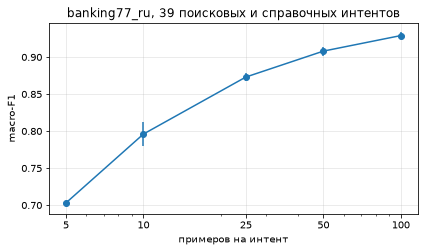

In [15]:
sub = b77ru[b77ru["group"].isin(["search", "faq"])]
tr, te = sub[sub["split"] == "train"], sub[sub["split"] == "test"]
te = te[~te["text"].map(normalize).isin(set(tr["text"].map(normalize)))]
print("интентов:", sub["intent"].nunique(), "| train:", len(tr), "| test без утечек:", len(te))
rows = []
for n in [5, 10, 25, 50, 100]:
    for rep_i in range(3):
        part = tr.sample(frac=1, random_state=SEED + rep_i).groupby("intent").head(n)
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=1, sublinear_tf=True)
        clf = LogisticRegression(max_iter=2000, C=10).fit(
            vec.fit_transform(part["text"].str.lower()), part["intent"]
        )
        pred = clf.predict(vec.transform(te["text"].str.lower()))
        rows.append({"n": n, "macro_f1": f1_score(te["intent"], pred, average="macro")})
lc = pd.DataFrame(rows).groupby("n")["macro_f1"].agg(["mean", "std"]).round(3)
print(lc)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(lc.index, lc["mean"], yerr=lc["std"], marker="o")
ax.set_xscale("log")
ax.set_xticks(lc.index, lc.index)
ax.set_xlabel("примеров на интент")
ax.set_ylabel("macro-F1")
ax.set_title("banking77_ru, 39 поисковых и справочных интентов")
save(fig, "14_banking77_ru_learning_curve.png")

**Выводы.**

- По ручной группировке поиском решаются 24 интента (3 765 строк, 28,8%), справкой — 15 (2 300, 17,6%), а 38 интентов (7 018, 53,6%) — тикеты-инциденты, которые поиск не решает. **Для проекта:** из словаря BANKING77 в тестовый набор поиска берём только 39 поисковых и справочных интентов.
- banking77_ru — перевод: медиана 8 слов против 10 у оригинала, коротких фраз до 4 слов 6,5% против 1,8%. Это всё ещё обращения, а не поисковые запросы. 2 строки остались без перевода.
- В русской версии 636 групп дублей (1 538 строк), 31 группа с разными интентами у одинакового текста, 12,1% тестовых фраз дословно есть в train. **Для проекта:** делим по нормализованному тексту, иначе метрики завышены.
- Кривая обучения на 39 интентах (test без утечек): macro-F1 0,703 при 5 примерах на интент, 0,873 при 25, 0,908 при 50, 0,929 при 100. Прирост после 50 мал — объём 50–100 кейсов на интент из BRD разумен.

## 5. Синтетический каталог фич Альфа-Банка

> **Допущение, не данные банка.** Каталог [`data/synthetic/alfa_feature_catalog.csv`](../data/synthetic/alfa_feature_catalog.csv) написан вручную: 48 карточек (продукты и разделы приложения), у каждой — раздел, описание, синонимы и связанные интенты BANKING77. Запросы трёх источников: короткие (≤ 6 слов) фразы banking77_ru поисковых и справочных интентов, финансовые запросы synthetic-search-queries-ru, сопоставленные с карточками регулярками, и шаблонные запросы по синонимам в четырёх стратах (чистый, опечатка, неверная раскладка, с брендом). Метки: целевая фича — 2, другая фича того же раздела — 1, остальные — 0. Ровно такой формат «запрос → ожидаемая фича, оценка 0/1/2» мы ждём от команды поиска. Внешние LLM API для генерации не используются: шаблоны и правила детерминированы.

Индекс бейзлайна — только название и описание карточки, синонимы в индекс не попадают: иначе шаблонные запросы находили бы сами себя.

In [16]:
print("карточек:", len(cat), "| разделов:", cat["section"].nunique())
print(cat["section"].value_counts().to_dict())
q_b = b77ru_queries(b77ru, cat)
q_s_all = ssq_queries(ssq)
q_s = q_s_all[q_s_all["targets"].str.len() > 0]
q_t = template_queries(cat)
print(
    "banking77_ru (≤ 6 слов):",
    len(q_b),
    "| ssq_ru: сопоставлено",
    len(q_s),
    "из",
    len(q_s_all),
    f"({len(q_s) / len(q_s_all):.1%}), остальные — вне каталога | шаблонных:",
    len(q_t),
)
queries = pd.concat([q_b, q_s, q_t], ignore_index=True)
queries["query_id"] = range(len(queries))
queries["n_words"] = n_words(queries["text"])
qrels_c = build_qrels(queries, cat)
print(
    "запросов:",
    len(queries),
    "| пар с меткой:",
    len(qrels_c),
    "| метки:",
    qrels_c["rel"].value_counts(normalize=True).round(3).to_dict(),
)
print("целей на запрос:", queries["targets"].str.len().value_counts().to_dict())
cover = queries.explode("targets")["targets"].value_counts()
print(
    "карточек без единого запроса:",
    len(set(cat["feature_id"]) - set(cover.index)),
    "| запросов на карточку min/median/max:",
    cover.min(),
    cover.median(),
    cover.max(),
)
print("медиана слов по источникам:", queries.groupby("source")["n_words"].median().to_dict())

карточек: 48 | разделов: 13
{'Карты': 7, 'Платежи и переводы': 7, 'Управление картой': 6, 'Пополнение': 5, 'Профиль и безопасность': 5, 'Валюта': 3, 'Справка': 3, 'Кредиты': 3, 'Сбережения': 3, 'Инвестиции': 2, 'Страхование': 2, 'Ипотека': 1, 'Налоги': 1}


banking77_ru (≤ 6 слов): 2160 | ssq_ru: сопоставлено 452 из 923 (49.0%), остальные — вне каталога | шаблонных: 852


запросов: 3464 | пар с меткой: 166272 | метки: {0: 0.901, 1: 0.078, 2: 0.021}
целей на запрос: {1: 3454, 2: 10}
карточек без единого запроса: 0 | запросов на карточку min/median/max: 16 69.5 222
медиана слов по источникам: {'banking77_ru': 5.0, 'ssq_ru': 8.0, 'шаблон': 2.0}


In [17]:
title = dict(zip(cat["feature_id"], cat["title"], strict=True))
show = pd.concat(
    [
        q_b.sample(2, random_state=1),
        q_s.sample(2, random_state=3),
        q_t[q_t["stratum"] != "чистый"].sample(3, random_state=2),
    ]
)
show.assign(цель=show["targets"].map(lambda t: ", ".join(title[x] for x in t)))[
    ["text", "source", "stratum", "цель"]
]

,text,source,stratum,цель
986,Получаю ли я физическую карту бесплатно?,banking77_ru,search,Дебетовая карта
389,В каких странах вы находитесь?,banking77_ru,faq,Поддерживаемые валюты и страны
418,"Инвестиции в размере 30000000, весной",ssq_ru,Real Estate Investment,Брокерский счёт
179,Ипотека летом с низким процентом,ssq_ru,Credit Services,Ипотека
823,оформить полис альфа,шаблон,с брендом,Страхование жизни и имущества
763,оформить инвестиции альфа,шаблон,с брендом,Брокерский счёт
2,"lt,tnjdfz rfhnf",шаблон,раскладка,Дебетовая карта


**Ручная проверка разметки.** Шаблонные запросы верны по построению (это синонимы карточки). Вручную проверены случайные 40 сопоставлений ssq_ru и 20 фраз banking77_ru (`random_state=42`). «Верно» — цель однозначна; «спорно» — запрос про услугу, которой у банка в таком виде нет (налоговые консультанты, данные о страховых случаях), или цель неоднозначна (перевод в евро — перевод или обмен); «ошибка» — цель неверна.

In [18]:
SSQ_CHECK = {  # индекс строки ssq → вердикт (проверено вручную)
    601: "верно",
    84: "верно",
    678: "верно",
    670: "верно",
    317: "спорно",
    390: "верно",
    582: "спорно",
    205: "спорно",
    812: "верно",
    72: "верно",
    144: "спорно",
    332: "спорно",
    290: "верно",
    745: "верно",
    719: "спорно",
    113: "верно",
    822: "верно",
    447: "верно",
    799: "спорно",
    166: "верно",
    152: "верно",
    262: "верно",
    490: "верно",
    234: "спорно",
    407: "спорно",
    428: "спорно",
    157: "верно",
    902: "верно",
    27: "верно",
    691: "верно",
    767: "ошибка",
    485: "верно",
    841: "верно",
    225: "верно",
    912: "верно",
    151: "ошибка",
    554: "спорно",
    641: "спорно",
    249: "спорно",
    155: "верно",
}
B77_CHECK = {  # индекс строки в q_b → вердикт
    2079: "верно",
    668: "верно",
    2073: "верно",
    1113: "верно",
    788: "спорно",
    1780: "верно",
    1672: "верно",
    1717: "верно",
    926: "верно",
    2157: "верно",
    674: "верно",
    2011: "верно",
    96: "спорно",
    1164: "верно",
    567: "верно",
    135: "верно",
    29: "верно",
    1641: "верно",
    1845: "верно",
    1940: "верно",
}
smp_s = q_s.sample(40, random_state=42)
smp_b = q_b.sample(20, random_state=42)
assert list(smp_s.index) == list(SSQ_CHECK), "выборка ssq изменилась"
assert list(smp_b.index) == list(B77_CHECK), "выборка banking77_ru изменилась"
for name, chk in [("ssq_ru", SSQ_CHECK), ("banking77_ru", B77_CHECK)]:
    print(name, pd.Series(chk).value_counts().to_dict())
bad_s = smp_s.assign(
    цель=smp_s["targets"].map(lambda t: ", ".join(title[x] for x in t)),
    вердикт=pd.Series(SSQ_CHECK),
)
print(bad_s[bad_s["вердикт"] != "верно"][["text", "цель", "вердикт"]].head(8).to_string())
bad_b = smp_b.assign(вердикт=pd.Series(B77_CHECK))
print(bad_b[bad_b["вердикт"] != "верно"][["text", "intent", "вердикт"]].to_string())

ssq_ru {'верно': 25, 'спорно': 13, 'ошибка': 2}
banking77_ru {'верно': 18, 'спорно': 2}
                                                                                                     text                   цель вердикт
317                                               Вложения в проекты в Беларуси на сумму до 2000 долларов        Брокерский счёт  спорно
582                         Какие компании по налоговому консультированию рекомендуют с оценкой 2 и выше?        Налоги и вычеты  спорно
205                                             Нужны услуги налоговых консультантов с хорошей репутацией        Налоги и вычеты  спорно
144  Подскажите компанию, которая занимается налогами и имеет рейтинг удовлетворенности клиентов отличный        Налоги и вычеты  спорно
332                                    Ищу налогового консультанта с высоким процентом довольных клиентов        Налоги и вычеты  спорно
719                                 Покажите инвестиционные объекты сделки которых заключа

In [19]:
docs_c = cat["doc"].tolist()
rankers = {
    "BM25 (псевдоосновы 5 букв)": BM25(docs_c, stem=5),
    "TF-IDF символьные 2–5": CharTfidf(docs_c),
}
runs_c, rows = {}, []
for name, rk in rankers.items():
    run = top_k_run(
        rk.scores(queries["text"].tolist()),
        queries["query_id"].tolist(),
        cat["feature_id"].tolist(),
        k=10,
    )
    m = evaluate_run(run, qrels_c).merge(queries[["query_id", "source", "stratum"]], on="query_id")
    top3 = run[run["position"] <= 3].merge(qrels_c, on=["query_id", "doc_id"])
    m = m.merge(
        top3.groupby("query_id")["rel"].apply(lambda s: (s == 2).sum() / 3).rename("r3_exact"),
        on="query_id",
    )
    hit1 = (
        run[run["position"] == 1]
        .merge(qrels_c, on=["query_id", "doc_id"])
        .set_index("query_id")["rel"]
    )
    m["top1_target"] = m["query_id"].map(hit1).eq(2)
    n_rel = qrels_c[qrels_c["rel"] > 0].groupby("query_id").size()
    m["r3_ceiling"] = m["query_id"].map(n_rel).clip(upper=3) / 3
    runs_c[name] = (run, m)
    for src, g in [("все", m), *list(m.groupby("source"))]:
        rows.append(
            {
                **ci_row(f"{name} | {src}", g),
                "потолок R3": round(g["r3_ceiling"].mean(), 3),
                "цель на 1-м месте": round(g["top1_target"].mean(), 3),
            }
        )
pd.DataFrame(rows)

,выдача,запросов,R3,NDCG@3,R3 строгий (rel=2),потолок R3,цель на 1-м месте
0,BM25 (псевдоосновы 5 букв) | все,3464,0.401 [0.391; 0.411],0.526 [0.514; 0.538],0.213,0.938,0.482
1,BM25 (псевдоосновы 5 букв) | banking77_ru,2160,0.410 [0.398; 0.424],0.525 [0.512; 0.540],0.219,1.000,0.512
2,BM25 (псевдоосновы 5 букв) | ssq_ru,452,0.398 [0.378; 0.418],0.624 [0.593; 0.656],0.235,0.636,0.425
3,BM25 (псевдоосновы 5 букв) | шаблон,852,0.380 [0.356; 0.405],0.475 [0.448; 0.501],0.185,0.941,0.437
4,TF-IDF символьные 2–5 | все,3464,0.439 [0.428; 0.449],0.575 [0.563; 0.588],0.231,0.938,0.542
5,TF-IDF символьные 2–5 | banking77_ru,2160,0.447 [0.434; 0.460],0.563 [0.549; 0.578],0.236,1.000,0.540
6,TF-IDF символьные 2–5 | ssq_ru,452,0.418 [0.397; 0.438],0.687 [0.654; 0.719],0.246,0.636,0.560
7,TF-IDF символьные 2–5 | шаблон,852,0.428 [0.405; 0.451],0.547 [0.521; 0.572],0.212,0.941,0.535


           TF-IDF NDCG@3  BM25 NDCG@3
stratum                              
опечатка           0.653        0.461
раскладка          0.122        0.115
с брендом          0.706        0.647
чистый             0.707        0.675


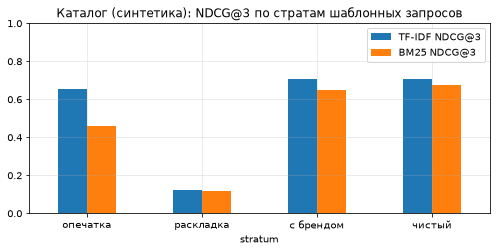

In [20]:
mt = runs_c["TF-IDF символьные 2–5"][1]
mb = runs_c["BM25 (псевдоосновы 5 букв)"][1]
st = pd.DataFrame(
    {
        "TF-IDF NDCG@3": mt[mt["source"] == "шаблон"].groupby("stratum")["ndcg3"].mean(),
        "BM25 NDCG@3": mb[mb["source"] == "шаблон"].groupby("stratum")["ndcg3"].mean(),
    }
).round(3)
print(st)
fig, ax = plt.subplots(figsize=(7, 3.6))
st.plot.bar(ax=ax, rot=0)
ax.set_title("Каталог (синтетика): NDCG@3 по стратам шаблонных запросов")
ax.set_ylim(0, 1)
save(fig, "15_catalog_strata.png")

**Шаблон EDA для данных банка на каталоге.** Выдачу TF-IDF по каталогу переводим в ожидаемый формат выгрузки банка (`BANK_SERP_COLUMNS`) и прогоняем ту же функцию `bank_eda`, которая будет запускаться на реальной выгрузке. Вердикт по выдаче: `ok`, если целевая фича в топ-3. Интент — интент BANKING77 или, для остальных источников, целевая фича.

In [21]:
run_t = runs_c["TF-IDF символьные 2–5"][0].merge(qrels_c, on=["query_id", "doc_id"])
qi = queries.set_index("query_id")
intent_of = qi["intent"].where(qi["intent"].notna(), "фича:" + qi["targets"].str[0])
ok = run_t[run_t["position"] <= 3].groupby("query_id")["rel"].max().eq(2)
serp_bank = pd.DataFrame(
    {
        "run_id": "synthetic-catalog",
        "platform": "android",
        "app_version": "0.0-synthetic",
        "query": run_t["query_id"].map(qi["text"]),
        "intent": run_t["query_id"].map(intent_of),
        "position": run_t["position"],
        "feature": run_t["doc_id"].map(title),
        "relevance": run_t["rel"],
        "verdict": run_t["query_id"].map(ok).map({True: "ok", False: "not_ok"}),
        "explanation": "синтетика: метка по правилу интент → фича",
    }
)[BANK_SERP_COLUMNS]
pd.Series(bank_eda(serp_bank))

прогонов                                              1
платформ / версий                                (1, 1)
запросов уникальных                                3179
интентов                                             87
запросов на интент min/median/max       (11, 24.0, 147)
интентов с < 50 запросами                            65
средняя длина выдачи                               10.0
доля релевантных в топ-3                          0.439
доля целевых (rel = 2) в топ-3                    0.231
доля вердиктов not_ok                             0.317
пустых объяснений                                     0
одинаковый текст с разными интентами                  7
dtype: object

**Выводы.**

- Каталог: 48 карточек в 13 разделах; 3 464 запроса (2 160 коротких фраз banking77_ru, 452 из 923 финансовых запросов ssq_ru, 852 шаблонных), у каждой карточки от 16 до 222 запросов. Пары: 90,1% — 0, 7,8% — 1, 2,1% — 2.
- Только 49,0% финансовых запросов ssq_ru удалось сопоставить с продуктом банка, остальные — про недвижимость, стартапы, «отчёты» и не имеют ответа в каталоге. Ручная проверка 40 сопоставлений: 25 верно, 13 спорно (налоговые консультанты, страховые случаи), 2 ошибки. banking77_ru: 18 из 20 верно, 2 спорно (шум исходной метки и непереведённая строка). **Для проекта:** GPT-сгенерированные запросы — только стресс-набор. Разметке банка нужна явная метка «нет подходящей фичи».
- Бейзлайн TF-IDF по символьным n-граммам: R3 = 0,439 [0,428; 0,449], NDCG@3 = 0,575 [0,563; 0,588], целевая фича на 1-м месте у 54,2% запросов. BM25 с псевдоосновами хуже: 0,401, 0,526 и 48,2%.
- Потолок R3 зависит от каталога: в разделе «Ипотека» одна карточка, и R3 больше 1/3 там недостижим. Средний потолок — 0,938, у ssq_ru — 0,636. **Для проекта:** R3 сравниваем только между прогонами одного каталога или нормируем на потолок, основной сигнал — NDCG@3.
- Страты: опечатка снижает NDCG@3 у TF-IDF с 0,707 до 0,653, у BM25 — до 0,461. Неверная раскладка ломает оба бейзлайна (0,122 и 0,115). **Для проекта:** страты «опечатка» и «раскладка» обязательны в тестовом наборе: на них поиск ломается первым.
- Шаблон EDA для выгрузки банка отработал без правок: 3 179 уникальных запросов, 87 интентов, у 65 из них меньше 50 запросов, 31,7% вердиктов not_ok, 7 одинаковых текстов с разными интентами.

## 6. MASSIVE ru-RU: контроль вне домена

Банковский поиск получает и запросы не про банк. Проверяем на разговорных русских командах MASSIVE, что бейзлайн по каталогу не поднимает банковские фичи с высоким скором для внедоменных запросов. Порог «уверенного» ответа — 5-й перцентиль скора топ-1 у доменных запросов каталога (banking77_ru и ssq_ru), где на первом месте стоит целевая фича: 95% правильных ответов выше порога.

финансовых фраз: 415 из 16521 (2.5%); {'qa_currency': 213, 'qa_stock': 202}
медиана слов: 5.0 | доля ≤ 4 слов: 0.359


порог: 0.227
внедоменных выше порога: 19.1% из 16106
медиана скора топ-1: доменные с целью на 1-м месте 0.381 / внедоменные 0.169

Внедоменные с самым высоким скором:
                           text  scenario                       фича  top1_score
     позвони по номеру телефона transport Перевод по номеру телефона       0.736
     статус доставки в domino's  takeaway             Доставка карты       0.654
позвони игорю на номер телефона     email Перевод по номеру телефона       0.583
   дай мне петин номер телефона     email Перевод по номеру телефона       0.582
      активировать wemo розетку       iot            Активация карты       0.555
    какой номер телефона у коли     email Перевод по номеру телефона       0.546
  какой номер телефона у андрея     email Перевод по номеру телефона       0.544
   какой у ольги номер телефона     email Перевод по номеру телефона       0.542

qa_currency: топ-1 «Курсы валют» или «Обмен валюты» у 56.8% из 213


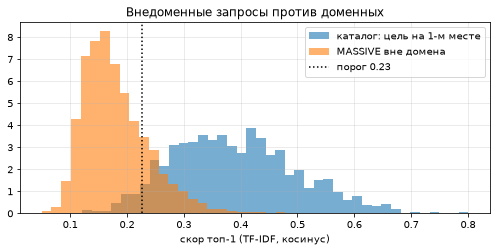

In [22]:
ru["n_words"] = n_words(ru["text"])
fin = ru["intent"].isin(["qa_currency", "qa_stock"])
print(
    f"финансовых фраз: {fin.sum()} из {len(ru)} ({fin.mean():.1%});",
    ru.loc[fin, "intent"].value_counts().to_dict(),
)
print(
    "медиана слов:",
    ru["n_words"].median(),
    "| доля ≤ 4 слов:",
    round((ru["n_words"] <= 4).mean(), 3),
)
tf = rankers["TF-IDF символьные 2–5"]
run_c, m_c = runs_c["TF-IDF символьные 2–5"]
top1 = run_c[run_c["position"] == 1].set_index("query_id")["score"]
ok_ids = m_c.loc[m_c["top1_target"] & (m_c["source"] != "шаблон"), "query_id"]
thr = float(np.quantile(top1.loc[ok_ids], 0.05))
s_ru = tf.scores(ru["text"].tolist())
ru["top1_score"] = s_ru.max(axis=1)
ru["top1_feature"] = np.asarray(cat["feature_id"])[s_ru.argmax(axis=1)]
ood = ru[~fin]
print(f"порог: {thr:.3f}")
print(f"внедоменных выше порога: {(ood['top1_score'] >= thr).mean():.1%} из {len(ood)}")
print(
    "медиана скора топ-1: доменные с целью на 1-м месте",
    round(top1.loc[ok_ids].median(), 3),
    "/ внедоменные",
    round(ood["top1_score"].median(), 3),
)
print("\nВнедоменные с самым высоким скором:")
top_ood = (
    ood.sort_values("top1_score", ascending=False)
    .head(8)
    .assign(фича=lambda d: d["top1_feature"].map(title))
)
print(top_ood[["text", "scenario", "фича", "top1_score"]].round(3).to_string(index=False))
cur_q = ru[ru["intent"] == "qa_currency"]
print(
    f"\nqa_currency: топ-1 «Курсы валют» или «Обмен валюты» у {cur_q['top1_feature'].isin(['F27', 'F26']).mean():.1%} из {len(cur_q)}"
)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(top1.loc[ok_ids], bins=40, alpha=0.6, density=True, label="каталог: цель на 1-м месте")
ax.hist(ood["top1_score"], bins=40, alpha=0.6, density=True, label="MASSIVE вне домена")
ax.axvline(thr, color="k", ls=":", label=f"порог {thr:.2f}")
ax.legend()
ax.set_xlabel("скор топ-1 (TF-IDF, косинус)")
ax.set_title("Внедоменные запросы против доменных")
save(fig, "16_massive_ood_scores.png")

**Выводы.**

- Финансовых фраз в MASSIVE ru — 415 из 16 521 (2,5%: курсы валют и акции). Медиана — 5 слов, 35,9% фраз не длиннее 4 слов: по форме это разговорный русский.
- 19,1% внедоменных фраз получают топ-1 со скором выше порога 0,227 — того же, что у 95% правильных доменных ответов. Типичный случай: «какой номер телефона у коли» → «Перевод по номеру телефона».
- Финансовые фразы qa_currency находят «Курсы валют» или «Обмен валюты» на 1-м месте только в 56,8% случаев.
- **Для проекта:** лексический поиск охотно отвечает на внедоменные запросы. В тестовый набор включаем внедоменную страту с ожидаемым ответом «нет релевантной фичи», а судья должен уметь сказать «ничего релевантного в топ-3».

## Итог: что EDA на прокси значит для проекта

1. **Основной прокси для метрик — WANDS**: короткие запросы (медиана 3 слова), шкала 0/1/2, реальная выдача. BM25 даёт NDCG@3 = 0,647 [0,613; 0,681] на 480 запросах — ширина интервала ±0,03 задаёт порядок минимальной заметной разницы между версиями.
2. **R3 без договорённости о «релевантном» вводит в заблуждение**: на WANDS 0,769 при rel ≥ 1 против 0,392 при rel = 2, на каталоге потолок R3 зависит от числа фич в разделе. Основная метрика выдачи — NDCG@3, R3 — вспомогательная.
3. **LLM-судья «из коробки» шумный**: на ESCI κ = 0,38–0,43, accuracy 0,61 по 4 классам и 0,82 по бинарной свёртке, половина ошибок — соседние классы. Калибруем на разметке Полины и меряем согласие и по шкале, и по свёртке «целевая / нет».
4. **Шум судьи — главный источник ложных тревог детектора**: при 5% ошибок precision 0,31 без кэша и 0,79 с кэшем вердиктов пар. Кэш и подтверждение изменения выдачи — обязательная часть детектора.
5. **Из банковских интентов поиском решается меньше половины** (46,4% строк BANKING77 — поиск и справка), остальное — тикеты. Тестовый набор строим из поисковых и справочных интентов, 50–100 кейсов на интент (macro-F1 0,908 при 50).
6. **Страты набора**: опечатка, неверная раскладка (NDCG@3 падает до 0,12), бренд, внедоменные запросы (19,1% получают уверенный банковский ответ) и запросы без целевой фичи (21% в WANDS, 51% у ssq_ru).
7. **Шаблон EDA и метрики готовы к данным банка**: формат «запрос → фича, 0/1/2» проверен на синтетическом каталоге, `bank_eda` и `evaluate_run` запускаются на выгрузке без правок.